# 00 · Data understanding and preprocessing

Inputs: the competition data and the `vd-utils` dataset (contains `vd_utils.py`).

The notebook explores the labelled data, builds the sequence-level split and exports the training frames.
Everything is written to `/kaggle/working/prep` and reused by all training notebooks (add this notebook's output as input):

| file | content |
|---|---|
| `frames.csv` | one row per labelled frame: clip, order in clip, original size, fold, export info |
| `annotations.csv.gz` | all boxes and ignore regions in original pixels |
| `train_masked/{images,labels}` | every `EXPORT_STEP`-th frame, ignore regions masked, long side ≤ 1344, YOLO labels |
| `anchors.json` | k-means anchor shapes for the anchor-based detectors |
| `figures/` | plots used in the report |

In [1]:
import os, sys, glob, json, warnings
from multiprocessing import Pool
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
from sklearn.model_selection import GroupKFold
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)

def find_utils():
    if os.path.exists("vd_utils.py"):
        return "."
    for depth in range(1, 6):
        hits = glob.glob(os.path.join("/kaggle/input", *["*"] * depth, "vd_utils.py"))
        if hits:
            return os.path.dirname(hits[0])
    raise FileNotFoundError("Add the vd-utils dataset as notebook input")

sys.path.insert(0, find_utils())
import vd_utils as U

In [2]:
# --- Configuration --------------------------------------------------------------
SEED = 42
N_FOLDS = 5          # GroupKFold over clips (train + val merged)
VAL_FOLD = 0         # holdout fold used for every model comparison
EXPORT_STEP = 5      # export every 5th frame; step-10 subset is used for model comparisons
LONG_SIDE = 1344     # max long side of exported training frames (multiple of 32)
COVER_THR = 0.5      # drop a GT box if >= 50% of it is inside a masked ignore region
U.seed_everything(SEED)

COMP = U.comp_root()
OUT = os.environ.get("VD_OUT", "/kaggle/working/prep")
FIG = os.path.join(OUT, "figures")
os.makedirs(FIG, exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG, name), dpi=120, bbox_inches="tight")
    plt.show()

print("competition data:", COMP)

competition data: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026


## 1. Load annotations

The provided `train` and `val` splits are merged (63 clips) and re-split by clip later.
Annotations are read from `annotations_coco.json` (pixels, `iscrowd=1` = ignore region).
The YOLO `labels/` folder of the competition holds the same boxes; it is used directly for validation in Ultralytics, so the counts are cross-checked below.

In [3]:
# --- Read COCO json of both labelled splits -----------------------------------
parts = [U.load_coco_split(s, COMP) for s in ["train", "val"]]
frames = pd.concat([p[0] for p in parts], ignore_index=True)
anns = pd.concat([p[1] for p in parts], ignore_index=True)
assert frames.key.is_unique, "clip names collide between train and val"

objs = anns[anns.iscrowd == 0].copy()
ign = anns[anns.iscrowd == 1]
objs["size"] = np.sqrt(objs.w * objs.h)                     # object scale in original pixels
objs["clip"] = objs.key.map(frames.set_index("key")["clip"])
frames["n_obj"] = frames.key.map(objs.groupby("key").size()).fillna(0).astype(int)
frames["n_ignore"] = frames.key.map(ign.groupby("key").size()).fillna(0).astype(int)

# cross-check: YOLO label files hold the same boxes as the COCO json (non-empty lines only)
check = frames.sample(200, random_state=SEED)
n_yolo = [sum(1 for l in open(U.label_path(os.path.join(COMP, p))) if l.strip()) for p in check.img_rel]
mismatch = check.assign(n_yolo=n_yolo).query("n_yolo != n_obj")
print(f"YOLO vs COCO box count mismatch: {len(mismatch)} / {len(check)} frames")
if len(mismatch):
    display(mismatch[["key", "n_obj", "n_yolo"]].head())

frames.groupby("split").agg(clips=("clip", "nunique"), frames=("key", "size"),
                            objects=("n_obj", "sum"), ignore_regions=("n_ignore", "sum"))

YOLO vs COCO box count mismatch: 0 / 200 frames


,clips,frames,objects,ignore_regions
split,,,,
train,56,24201,1105516,510744
val,7,2846,114132,31960


## 2. Image resolution (labelled vs test)

Resolution decides the input size: a fixed `imgsz` shrinks objects much more in 1920×1080 clips than in 960×540 ones.

In [4]:
# --- Resolution per clip, labelled and test -------------------------------------
test = pd.read_csv(os.path.join(COMP, "test_images.csv"))
res = pd.concat([
    frames.groupby("clip").first().assign(set="labelled").rename(columns={"orig_w": "width", "orig_h": "height"}),
    test.groupby("clip").first().assign(set="test"),
])
res["resolution"] = res.width.astype(str) + "x" + res.height.astype(str)
pd.crosstab(res.resolution, res.set, margins=True).sort_values("All", ascending=False)

set,labelled,test,All
resolution,,,
All,63,48,111
1904x1071,32,0,32
1344x756,13,7,20
1360x764,0,18,18
2688x1512,12,0,12
1920x1080,1,11,12
960x540,0,5,5
1904x1072,0,4,4
680x382,0,3,3


## 3. Class distribution

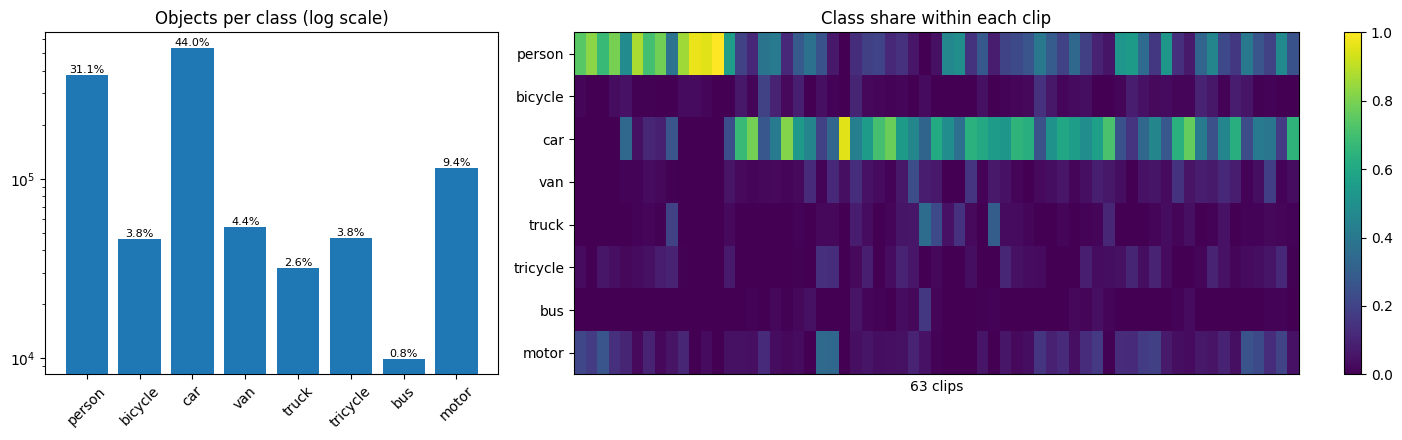

In [5]:
# --- Overall class counts and per-clip class share ------------------------------
counts = objs.cls.value_counts().reindex(range(U.NUM_CLASSES), fill_value=0)
share = objs.groupby(["clip", "cls"]).size().unstack(fill_value=0).reindex(columns=range(8), fill_value=0)
share = share.div(share.sum(1), axis=0)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 2]})
ax[0].bar(U.CLASSES, counts.values, color="tab:blue")
ax[0].set_yscale("log"); ax[0].set_title("Objects per class (log scale)"); ax[0].tick_params(axis="x", rotation=45)
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f"{v / counts.sum():.1%}", ha="center", va="bottom", fontsize=8)
im = ax[1].imshow(share.T.values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax[1].set_yticks(range(8), U.CLASSES); ax[1].set_xticks([]); ax[1].set_xlabel(f"{len(share)} clips")
ax[1].set_title("Class share within each clip"); plt.colorbar(im, ax=ax[1])
savefig("class_distribution.png")

## 4. Object sizes

Size is measured as $\sqrt{w h}$ in original pixels. COCO size buckets define `AP_small`.
The second table shows what happens after resizing a frame to a given input size: the share of objects that shrink below 8 and 16 px tells how much resolution the detector needs.

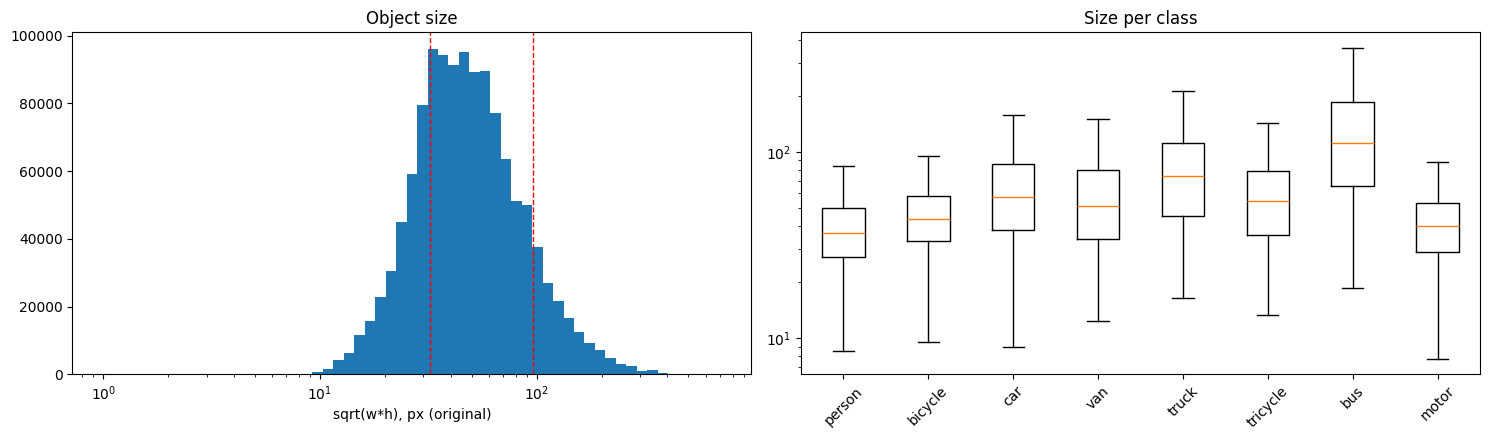

,person,bicycle,car,van,truck,tricycle,bus,motor
median_px,36.661,43.863,57.55,51.284,73.939,54.498,111.669,39.799
p10,20.494,25.826,28.39,28.723,33.118,24.980,41.833,20.347
p90,63.000,75.651,121.75,128.567,181.444,104.379,264.683,68.535


bucket,medium,small,large
share of objects,0.64,0.244,0.116


In [6]:
# --- Size distribution per class and COCO size buckets --------------------------
objs["bucket"] = pd.cut(objs.w * objs.h, [0, 32**2, 96**2, np.inf], labels=["small", "medium", "large"])
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].hist(objs["size"], bins=np.logspace(0, np.log10(objs["size"].max()), 60), color="tab:blue")
ax[0].set_xscale("log"); ax[0].set_xlabel("sqrt(w*h), px (original)"); ax[0].set_title("Object size")
for t in (32, 96):
    ax[0].axvline(t, color="red", ls="--", lw=1)
ax[1].boxplot([objs.loc[objs.cls == c, "size"] for c in range(8)], showfliers=False)
ax[1].set_xticks(range(1, 9), U.CLASSES, rotation=45); ax[1].set_yscale("log"); ax[1].set_title("Size per class")
savefig("object_sizes.png")

size_tab = objs.groupby("cls").agg(median_px=("size", "median"), p10=("size", lambda s: s.quantile(.1)),
                                   p90=("size", lambda s: s.quantile(.9)))
size_tab.index = U.CLASSES
display(size_tab.T)
display(objs.bucket.value_counts(normalize=True).rename("share of objects").to_frame().T)

In [7]:
# --- Effective object size after resizing the long side to a given input size ----
long_side = objs.key.map(frames.set_index("key")[["orig_w", "orig_h"]].max(1))
rows = []
for imgsz in [640, 1024, 1344, 1920]:
    eff = objs["size"] * np.minimum(1, imgsz / long_side)
    rows.append({"input long side": imgsz, "median px": eff.median(),
                 "< 8 px": (eff < 8).mean(), "< 16 px": (eff < 16).mean()})
pd.DataFrame(rows).set_index("input long side")

,median px,< 8 px,< 16 px
input long side,,,
640,15.286,9.738e-02,0.536
1024,24.457,1.415e-02,0.199
1344,32.100,5.048e-03,0.082
1920,42.131,2.599e-04,0.029


## 5. Scene density (objects per frame)

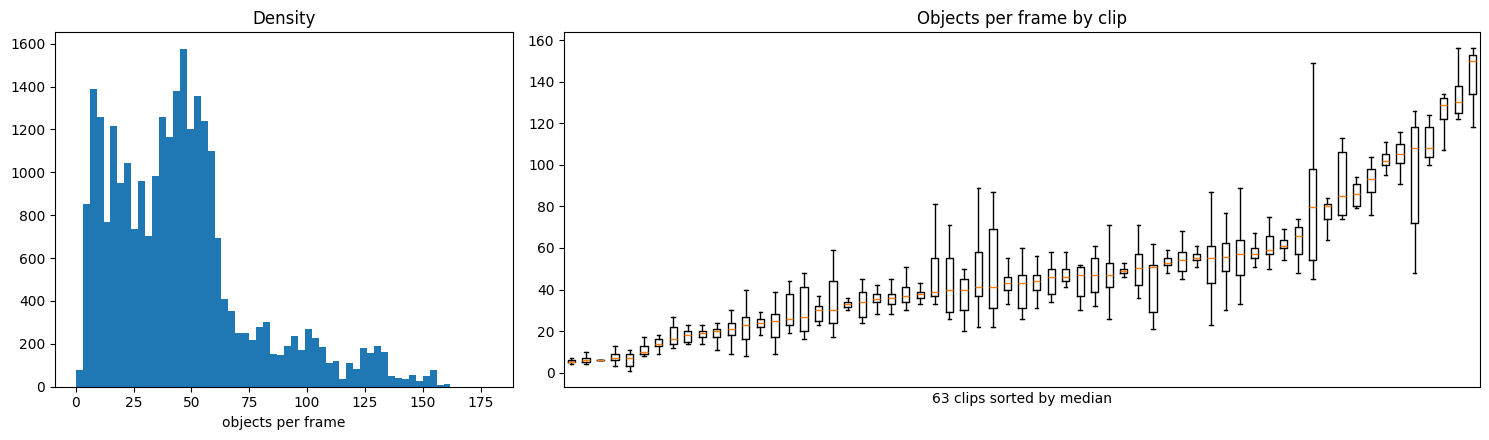

,count,mean,std,min,50%,90%,99%,max
objects per frame,27047.0,45.094,31.147,0.0,42.0,90.0,140.0,180.0


In [8]:
# --- Objects per frame, overall and per clip -------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 2]})
ax[0].hist(frames.n_obj, bins=60, color="tab:blue"); ax[0].set_xlabel("objects per frame"); ax[0].set_title("Density")
order = frames.groupby("clip").n_obj.median().sort_values().index
ax[1].boxplot([frames.loc[frames["clip"] == c, "n_obj"] for c in order], showfliers=False)
ax[1].set_xticks([]); ax[1].set_xlabel(f"{len(order)} clips sorted by median"); ax[1].set_title("Objects per frame by clip")
savefig("objects_per_frame.png")
frames.n_obj.describe(percentiles=[.5, .9, .99]).to_frame("objects per frame").T

## 6. Ignore regions

In [9]:
# --- How often and how much of the frame is marked as ignore ----------------------
area = ign.assign(a=ign.w * ign.h).groupby("key").a.sum()
frac = (frames.key.map(area).fillna(0) / (frames.orig_w * frames.orig_h)).clip(0, 1)
pd.Series({"frames with ignore regions": (frames.n_ignore > 0).mean(),
           "mean covered area (all frames)": frac.mean(),
           "p90 covered area": frac.quantile(.9)}).to_frame("value").T

,frames with ignore regions,mean covered area (all frames),p90 covered area
value,0.722,0.172,0.474


## 7. Temporal redundancy -> frame subsampling step

Consecutive frames of a clip are nearly identical. Using `track_id`, the IoU of the same object between frame *t* and *t + k* measures how much new information the next sampled frame adds.

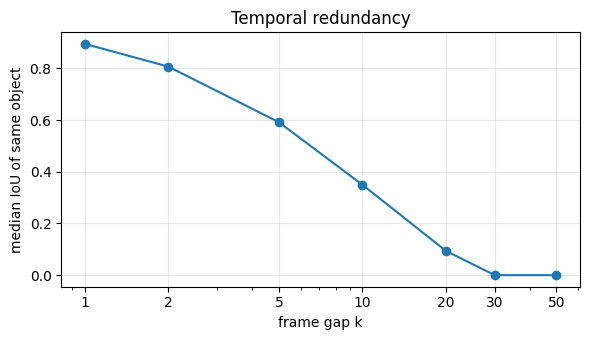

,median IoU,IoU > 0.5,pairs
gap k,,,
1,0.895,0.953,297859
2,0.807,0.851,295820
5,0.592,0.587,289773
10,0.350,0.387,279771
20,0.094,0.254,260853
30,0.000,0.206,243121
50,0.000,0.168,211097


In [10]:
# --- IoU of the same track between frames k apart --------------------------------
tr = objs[objs.track_id >= 0].merge(frames[["key", "frame_idx"]], on="key")[["clip", "track_id", "frame_idx", "x", "y", "w", "h"]]
tr = tr.sample(min(len(tr), 300_000), random_state=SEED)
full = objs[objs.track_id >= 0].merge(frames[["key", "frame_idx"]], on="key")[["clip", "track_id", "frame_idx", "x", "y", "w", "h"]]

def pair_iou(a, b):
    ix = np.clip(np.minimum(a.x + a.w, b.x + b.w) - np.maximum(a.x, b.x), 0, None)
    iy = np.clip(np.minimum(a.y + a.h, b.y + b.h) - np.maximum(a.y, b.y), 0, None)
    inter = ix * iy
    return inter / (a.w * a.h + b.w * b.h - inter)

gaps, rows = [1, 2, 5, 10, 20, 30, 50], []
for k in gaps:
    m = tr.merge(full.assign(frame_idx=full.frame_idx - k), on=["clip", "track_id", "frame_idx"], suffixes=("", "_k"))
    b = m[["x_k", "y_k", "w_k", "h_k"]].set_axis(["x", "y", "w", "h"], axis=1)
    iou = pair_iou(m[["x", "y", "w", "h"]], b)
    rows.append({"gap k": k, "median IoU": iou.median(), "IoU > 0.5": (iou > 0.5).mean(), "pairs": len(m)})
redund = pd.DataFrame(rows).set_index("gap k")

plt.figure(figsize=(6, 3.5))
plt.plot(redund.index, redund["median IoU"], "o-")
plt.xscale("log"); plt.xticks(gaps, gaps); plt.xlabel("frame gap k"); plt.ylabel("median IoU of same object")
plt.title("Temporal redundancy"); plt.grid(alpha=.3)
savefig("temporal_redundancy.png")
redund

## 8. Sequence-level split

All frames of one clip go to the same fold (`GroupKFold`, groups = clip), so no frame of a validation clip is seen in training.
Fold `VAL_FOLD` is the holdout for every model comparison; the table checks that folds are similar in size, density and object scale.

In [11]:
# --- GroupKFold over clips -----------------------------------------------------------
clip_tab = frames.groupby("clip").agg(n_frames=("key", "size"), n_obj=("n_obj", "sum")).reset_index()
gkf = GroupKFold(n_splits=N_FOLDS)
clip_tab["fold"] = -1
for f, (_, idx) in enumerate(gkf.split(clip_tab, groups=clip_tab["clip"])):
    clip_tab.loc[idx, "fold"] = f
frames["fold"] = frames["clip"].map(clip_tab.set_index("clip").fold)
objs["fold"] = objs.key.map(frames.set_index("key").fold)

fold_tab = frames.groupby("fold").agg(clips=("clip", "nunique"), frames=("key", "size"), obj_per_frame=("n_obj", "mean"))
fold_tab["small share"] = objs.groupby("fold").bucket.apply(lambda b: (b == "small").mean())
fold_tab = fold_tab.join(objs.groupby(["fold", "cls"]).size().unstack().pipe(lambda t: t.div(t.sum(1), axis=0)).set_axis(U.CLASSES, axis=1))
fold_tab

,clips,frames,obj_per_frame,small share,person,bicycle,car,van,truck,tricycle,bus,motor
fold,,,,,,,,,,,,
0,13,5682,38.011,0.288,0.296,0.025,0.486,0.052,0.014,0.047,0.005,0.076
1,13,4929,41.943,0.181,0.358,0.039,0.333,0.033,0.063,0.044,0.004,0.125
2,13,6408,44.999,0.261,0.353,0.052,0.414,0.039,0.012,0.031,0.009,0.091
3,12,5361,45.563,0.252,0.244,0.043,0.492,0.072,0.020,0.031,0.011,0.088
4,12,4667,56.635,0.232,0.302,0.028,0.469,0.027,0.028,0.042,0.011,0.093


## 9. Anchor shapes from the data (for RetinaNet / Faster R-CNN)

Following YOLOv2, box shapes are clustered with k-means using $1 - \text{IoU}$ as the distance.
Only boxes from the **training part of the holdout split** (folds ≠ `VAL_FOLD`, step-10 frames) are used, scaled to the exported resolution (long side ≤ 1344), which is the resolution the torchvision models see.
The default torchvision anchors (sizes 32–512) are compared by mean best IoU.

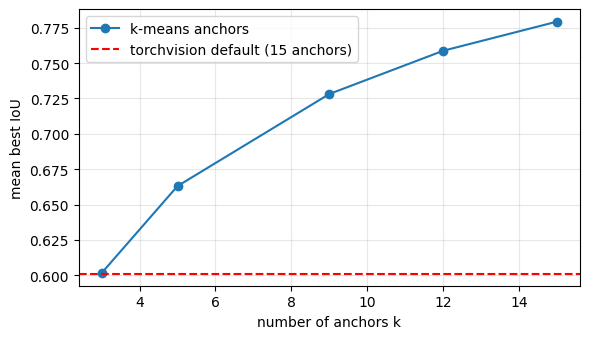

{'fit_on': 'folds != 0, step 10, long side 1344',
 'kmeans9_wh': [[11.3, 15.5],
  [22.6, 19.8],
  [15.5, 30.4],
  [41.0, 23.5],
  [22.0, 44.0],
  [31.1, 32.5],
  [63.7, 36.7],
  [40.9, 57.9],
  [102.4, 77.0]],
 'retinanet_sizes': [[8.7, 13.2, 16.1],
  [18.3, 22.0, 24.7],
  [27.7, 28.4, 32.8],
  [39.7, 44.1, 45.5],
  [67.7, 68.1, 112.4]],
 'aspect_ratios_h_over_w': [0.57, 1.09, 2.05],
 'mean_iou': {'default': 0.601, 'data_driven': 0.821}}

In [12]:
# --- k-means anchors on the training folds only ----------------------------------
fit = U.select_frames(frames, folds=[f for f in range(N_FOLDS) if f != VAL_FOLD], step=10)
b = objs[objs.key.isin(fit.key)].merge(fit[["key", "orig_w", "orig_h"]], on="key")
s = np.minimum(1, LONG_SIDE / b[["orig_w", "orig_h"]].max(1).values)
wh = np.stack([b.w * s, b.h * s], 1)
wh = wh[(wh > 1).all(1)]
wh = wh[np.random.default_rng(SEED).choice(len(wh), min(len(wh), 100_000), replace=False)]

ks = [3, 5, 9, 12, 15]
fits = {k: U.kmeans_anchors(wh, k) for k in ks}
default_iou = U.wh_iou(wh, U.anchor_wh([32, 64, 128, 256, 512], [0.5, 1.0, 2.0])).max(1).mean()

# RetinaNet: 5 levels (P3-P7) x 3 sizes, shared aspect ratios (h / w)
c15 = fits[15][0]
retina_sizes = [sorted(np.sqrt(c15[3 * i:3 * i + 3].prod(1)).round(1).tolist()) for i in range(5)]
ratios = np.quantile(wh[:, 1] / wh[:, 0], [0.15, 0.5, 0.85]).round(2).tolist()
tuned_iou = U.wh_iou(wh, U.anchor_wh(sum(retina_sizes, []), ratios)).max(1).mean()

plt.figure(figsize=(6, 3.5))
plt.plot(ks, [fits[k][1] for k in ks], "o-", label="k-means anchors")
plt.axhline(default_iou, color="red", ls="--", label="torchvision default (15 anchors)")
plt.xlabel("number of anchors k"); plt.ylabel("mean best IoU"); plt.legend(); plt.grid(alpha=.3)
savefig("anchor_kmeans.png")

anchors = {"fit_on": f"folds != {VAL_FOLD}, step 10, long side {LONG_SIDE}",
           "kmeans9_wh": fits[9][0].round(1).tolist(),
           "retinanet_sizes": retina_sizes, "aspect_ratios_h_over_w": ratios,
           "mean_iou": {"default": round(float(default_iou), 3), "data_driven": round(float(tuned_iou), 3)}}
with open(os.path.join(OUT, "anchors.json"), "w") as f:
    json.dump(anchors, f, indent=1)
anchors

## 10. Export training frames

For every `EXPORT_STEP`-th frame of every clip:
1. **Ignore regions are painted gray** (value 114), so crowds and dense parking lots are neither positives nor background. GT boxes that are ≥ 50 % hidden by a mask are dropped.
2. **Resized** so the long side is ≤ 1344 (`INTER_AREA`), which keeps decoding cheap during training. Smaller clips are not upscaled.
3. **YOLO labels** are written next to the images. Normalised coordinates do not change with resizing.

Validation and test always use the **original, unmasked** images; ignore regions are handled by the evaluator (`iscrowd=1`).
Normalisation (ImageNet mean/std or /255) and augmentation are done by each framework at training time and are described in its notebook.

In [13]:
# --- Build export tasks and run them on all CPU cores -------------------------------
exp = frames[frames.frame_idx % EXPORT_STEP == 0]
box_by_key = {k: g[["cls", "x", "y", "w", "h"]].values for k, g in objs.groupby("key")}
ign_by_key = {k: g[["x", "y", "w", "h"]].values for k, g in ign.groupby("key")}
tasks = [{"key": r.key, "src": os.path.join(COMP, r.img_rel),
          "dst_img": os.path.join(OUT, "train_masked", "images", r.clip, r.stem + ".jpg"),
          "dst_lbl": os.path.join(OUT, "train_masked", "labels", r.clip, r.stem + ".txt"),
          "boxes": box_by_key.get(r.key, np.zeros((0, 5))), "regions": ign_by_key.get(r.key, np.zeros((0, 4))),
          "long_side": LONG_SIDE, "cover_thr": COVER_THR} for r in exp.itertuples()]

with Pool(os.cpu_count()) as pool:
    done = pd.DataFrame(pool.map(U.export_frame, tasks, chunksize=16))

frames = frames.merge(done, on="key", how="left")
frames["exported"] = frames.new_w.notna()
print(f"exported {len(done)} frames | boxes kept {done.n_kept.sum()} | "
      f"dropped {done.n_dropped.sum()} ({done.n_dropped.sum() / (done.n_kept.sum() + done.n_dropped.sum()):.2%})")

exported 5439 frames | boxes kept 238865 | dropped 6920 (2.82%)


## 11. Verify the conversion

Left: original frame with COCO boxes and ignore regions (gray). Right: exported frame with boxes read back from the written YOLO label file.
Matching boxes confirm that coordinates, class ids and masking are correct.

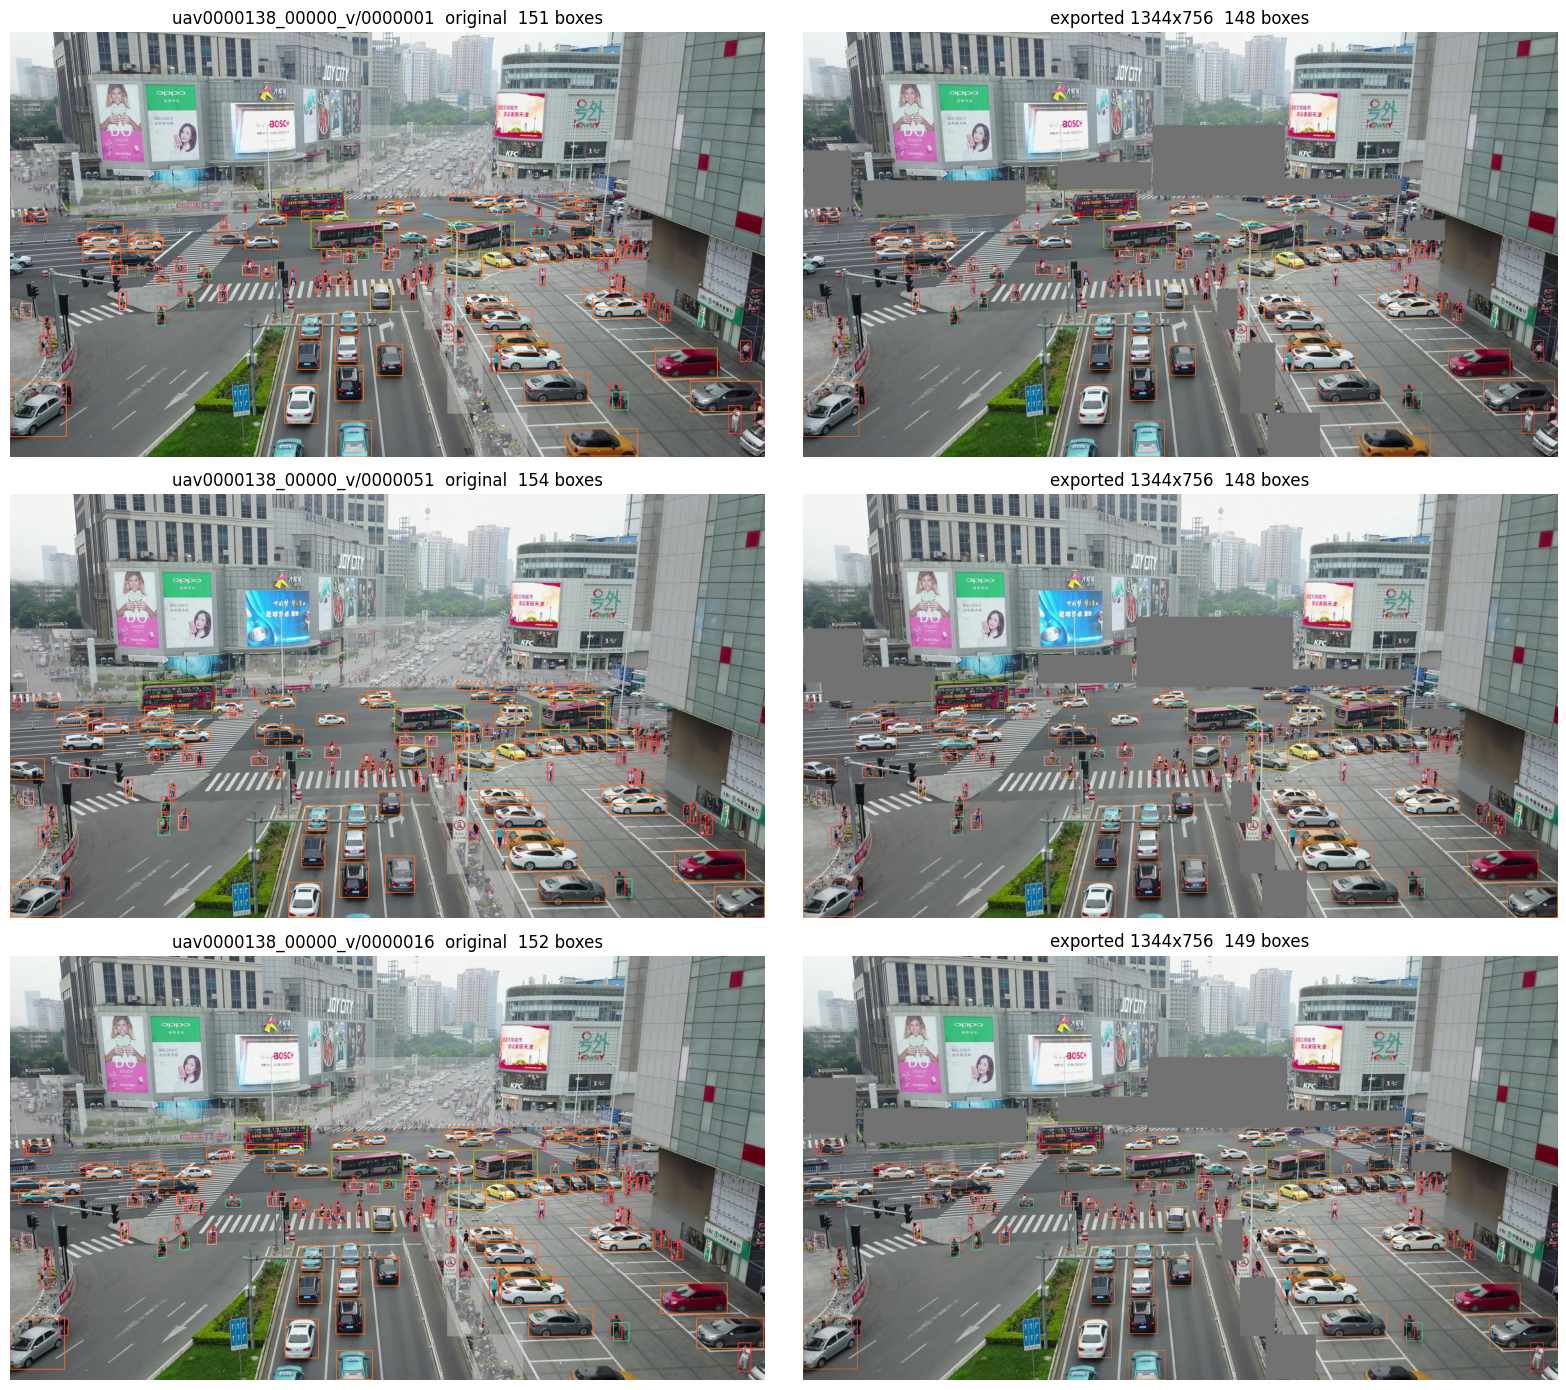

In [14]:
# --- Ground truth before vs after export on frames with many objects and ignore regions ---
cand = frames[frames.exported & (frames.n_ignore > 0)]
show = (cand if len(cand) else frames[frames.exported]).nlargest(30, "n_obj").sample(3, random_state=SEED)
fig, ax = plt.subplots(3, 2, figsize=(16, 14))
for i, r in enumerate(show.itertuples()):
    o = objs[objs.key == r.key]
    orig = cv2.imread(os.path.join(COMP, r.img_rel))
    ax[i, 0].imshow(U.draw_boxes(orig, np.c_[o.x, o.y, o.x + o.w, o.y + o.h], o.cls.values,
                                 ign[ign.key == r.key][["x", "y", "w", "h"]].values))
    ax[i, 0].set_title(f"{r.key}  original  {o.shape[0]} boxes")
    img_p = os.path.join(OUT, "train_masked", "images", r.clip, r.stem + ".jpg")
    im = cv2.imread(img_p)
    bx, cl = U.read_yolo_labels(U.label_path(img_p), im.shape[1], im.shape[0])
    ax[i, 1].imshow(U.draw_boxes(im, bx, cl, thickness=1))
    ax[i, 1].set_title(f"exported {im.shape[1]}x{im.shape[0]}  {len(bx)} boxes")
for a in ax.ravel():
    a.axis("off")
savefig("gt_verification.png")

In [15]:
# --- Save tables for the training notebooks -----------------------------------------
frames.to_csv(os.path.join(OUT, "frames.csv"), index=False)
anns.to_csv(os.path.join(OUT, "annotations.csv.gz"), index=False)
clip_tab.to_csv(os.path.join(OUT, "splits.csv"), index=False)
sel = U.select_frames(frames, step=10)
print("comparison protocol (step 10):",
      f"train {(sel.fold != VAL_FOLD).sum()} frames, val {(sel.fold == VAL_FOLD).sum()} frames")
print("saved:", sorted(os.listdir(OUT)))

comparison protocol (step 10): train 2161 frames, val 573 frames
saved: ['anchors.json', 'annotations.csv.gz', 'figures', 'frames.csv', 'splits.csv', 'train_masked']


## 12. Observations -> decisions

| observation | number | decision |
|---|---|---|
| **Resolution shift.** Labelled clips are mostly high-res (32 × 1904×1071, 16 × ≥ 2688 px wide); 33 of 48 test clips are ≤ 1360 px wide and none is above 1920. | 16 / 63 labelled vs 33 / 48 test clips with long side ≤ 1360 | Train on frames resized to a fixed long side (≤ 1344) with scale augmentation; tune the test-time input size on validation in the final pipeline. |
| **Class imbalance.** `car` 44 %, `person` 31 %, `motor` 9 %; `van`, `bicycle`, `tricycle` ≈ 4 % each, `truck` 2.6 %, `bus` 0.8 %. Class mix varies strongly between clips (heatmap). | — | Report per-class AP for every model; expect low AP on rare classes. No resampling in the required comparisons. |
| **Small objects.** Median size 37–58 px for person/car in original pixels; 24 % of objects are COCO-small. After resizing the long side to 640, 54 % of objects are < 16 px and 10 % < 8 px; at 1024 these drop to 20 % and 1.4 %. | median 15 px at 640, 24 px at 1024, 32 px at 1344 | Input ≥ 1024 for YOLO/RT-DETR, 1344 for the torchvision models; a stride-4 head (P2) is tested. |
| **Anchors.** The smallest default torchvision anchor (32 px) equals the median object at 1344 px; k-means anchors (9 shapes, 11×16 to 102×77 px) cover the boxes much better. | mean best IoU 0.60 (default) vs 0.82 (data-driven) | Faster R-CNN: anchor sizes 16–256; RetinaNet: k-means sizes and aspect ratios from `anchors.json`. |
| **Density.** Mean 45 objects per frame, p99 140, max 180. | — | 500 detections per image for all models (the leaderboard limit); RT-DETR's 300 queries exceed the max object count, the number of queries is still tuned. |
| **Ignore regions.** Present in 72 % of frames, covering 17 % of the image on average (p90 47 %). | 2.8 % of boxes dropped as ≥ 50 % masked | Masked gray in training images; `iscrowd = 1` in evaluation so detections there are not penalised. |
| **Temporal redundancy.** The same object keeps IoU 0.90 between adjacent frames, but only 0.59 at gap 5 and 0.35 at gap 10 (the drone moves). | — | Step 10 (2 161 train frames) for the model comparisons is a compute trade-off rather than "free": step 5 is tested as a data change in the final pipeline. |
| **Split.** 5 GroupKFold folds of 12–13 clips; fold 0 has the lowest density (38 vs 42–57 objects per frame) and the highest small-object share (29 %). | YOLO vs COCO labels: 0 / 200 mismatches | Fold 0 is a slightly harder holdout; the same fold and frames are used for every model. |